## ARM KAZR Cloud Persistence Project: Cloud-State Construction

**Alec Blevins**
**STA 496 - Fall 2026**

### Purpose
This notebook begins the next stage of the project: turning the QC-processed ARM KAZR files into a time series describing whether clouds are present and how the detected cloud structure changes over time. 

The goal here is **exploration and validation**, not to finalize the modeling dataset. We will construct a transparent timestamp-level cloud-state table, inspect the time axis and state distribution, and summarize observed cloud-clear runs. 

### Where we are in the pipeline
1. **Data preparation — completed:** `preprocessing.py` selects the variables needed from the original ARM KAZRARSCL files and writes interim daily files.
2. **QC investigation — completed for initial design:** `02_qc_investigation.ipynb` documents the ARM availability flags, measurement QC fields, clutter categories, sentinel values, and annual data checks.
3. **QC application — initial implementation tested:** `src/qc.py` creates a QC-stage file, masking selected radar measurements while preserving timestamps and cloud-layer variables. Three daily files have been checked against the original data.
4. **Cloud-state construction — this notebook:** create one record per timestamp for the three test days (January 1–3, 2024), then inspect state coverage, continuity, and event durations.
5. **Later stages:** decide on temporal aggregation, engineer predictors, define a future target, and connect the steps in an end-to-end builder.

## Key choices for this notebook
- Use the ARM `cloud_layer_base_height` product to define the primary cloud state. A radar reflectivity return is **not** required for a timestamp to be labeled cloudy, because cloud-layer detections use combined radar and micropulse-lidar information.
- A timestamp is **cloudy** when at least one layer base is nonnegative.
- A timestamp is **clear** when all ten layer-base slots equal the documented `-1` clear-sky sentinel.
- A timestamp is **unknown** if neither rule applies (for example, an unexpected sentinel or missing value prevents a confident classification).
- Use only the three QC-processed test files while developing these steps. This notebook does not write new NetCDF files.

In this notebook, we will not yet choose a final aggregation interval, persistence horizon, or final predictor list. 

## 1. Imports and project paths

In [1]:
#Assumes notebook is run from the project root or notebooks subdirectory

#Library import
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

#Find project root without hardcoding the path
_start = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        candidate
        for candidate in [_start, *_start.parents]
        if (candidate / "ARM_DATA" / "2024-2025").is_dir()
    ),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find ARM_DATA/2024-2025 from the current directory. "
        "Run this notebook from the project root or a subdirectory of it."
    )

QC_DATA_DIR = (
    PROJECT_ROOT
    / "ARM_DATA"
    / "2024-2025"
    / "qc"
    / "sgparsclkazr1kolliasC1.c0"
)

#Develop on the three QC dates first; no first year. 
TEST_DATES = ["20240101", "20240102", "20240103"]
QC_FILES = {date: QC_DATA_DIR / f"kazr_{date}.nc" for date in TEST_DATES} #Grab

missing_files = [path for path in QC_FILES.values() if not path.is_file()]
if missing_files: #Slight catch for missing files
    missing_text = "\n".join(str(path) for path in missing_files)
    raise FileNotFoundError(
        "Some expected QC files were not found:\n"
        f"{missing_text}\n\n"
        "Check QC_DATA_DIR. If the files are in qc_test, change that path."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"QC input directory: {QC_DATA_DIR}")
print(f"Test files found: {len(QC_FILES)}")
for date, path in QC_FILES.items():
    print(f"  {date}: {path.name}")

Project root: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling
QC input directory: C:\Users\alecp\MyPrograms\STA 496\ARM_Cloud_Modeling\ARM_DATA\2024-2025\qc\sgparsclkazr1kolliasC1.c0
Test files found: 3
  20240101: kazr_20240101.nc
  20240102: kazr_20240102.nc
  20240103: kazr_20240103.nc


## 2. Reconfirm the variables and sentinel values

Before constructing a state label, we should inspect the variables and define it. The base and top fields have dimensions `(time, layer)`, with ten possible layer slots per timestamp. According to the ARM metadata, `-1` in the layer-base field indicates clear sky; nonnegative values represent detected layer bases. 

This does differ from radar reflectivity. A missing reflectivity value means there is no usable reflectivity measurement in that cell; it does not, on its own, establish that the atmosphere is clear. 

In [2]:
sample_file = QC_FILES[TEST_DATES[0]]

with xr.open_dataset(sample_file) as sample: #Open test files
    print("Dimensions:")
    for name, size in sample.sizes.items():
        print(f"  {name}: {size:,}")

    for variable in [
        "cloud_layer_base_height",
        "cloud_layer_top_height",
        "kazr_available",
    ]:
        print(f"\n{variable}")
        print("  dimensions:", sample[variable].dims) #Confirm dimensionality of the variable
        print("  attributes:", sample[variable].attrs)

    base_values = sample["cloud_layer_base_height"].values
    values, counts = np.unique(base_values, return_counts=True)
    sentinel_summary = pd.DataFrame({"value": values, "count": counts})
    print("\nMost frequent layer-base values:")
    display(sentinel_summary.sort_values("count", ascending=False).head(10))

Dimensions:
  time: 21,600
  height: 596
  layer: 10

cloud_layer_base_height
  dimensions: ('time', 'layer')
  attributes: {'long_name': 'Base height of hydrometeor layers for up to 10 layers, based on combined radar and micropulse lidar observations', 'units': 'm', 'valid_range': array([    0., 25000.], dtype=float32), 'flag_values': np.float32(-1.0), 'flag_meanings': 'clear_sky'}

cloud_layer_top_height
  dimensions: ('time', 'layer')
  attributes: {'long_name': 'Top height of hydrometeor layers for up to 10 layers, based on combined radar and micropulse lidar observations', 'units': 'm', 'valid_range': array([    0., 25000.], dtype=float32), 'flag_values': np.float32(-1.0), 'flag_meanings': 'clear_sky'}

kazr_available
  dimensions: ('time',)
  attributes: {'long_name': 'KAZR instrument availability decoded from the availability bit field', 'units': '1', 'flag_values': array([0, 1], dtype=int8), 'flag_meanings': 'unavailable available', 'comment': 'Derived from bit mask 1 of instru

,value,count
0,-1.0,189227
1,160.0,4712
6,370.0,3285
7,400.0,2241
5,340.0,2087
8,430.0,1698
9,460.0,1082
4,310.0,752
2,250.0,655
3,280.0,632


## Define the cloud-state rules

We need a reproducible rule to translate the ten layer slots into one state per timestamp. 

| Condition | `cloud_state` | Meaning |
|---|---:|---|
| At least one layer base is `>= 0` | `1` | Cloudy |
| All layer bases equal `-1` | `0` | Clear |
| Neither condition is true | `-1` | Unknown / needs review |

Here, the `unknown` state is deliberate. If a timestamp contains a missing or unexpected code, we should review. 

In [3]:
#Here, we will contruct a function to derive cloud state from the dataset
def construct_cloud_state(ds: xr.Dataset) -> pd.DataFrame:
    """Create timestamp-level cloud state and basic cloud-structure summaries.

    Cloud-state rule:
      1 = at least one nonnegative layer base (cloudy)
      0 = all layer bases equal -1 (clear)
     -1 = neither rule applies (unknown / needs review)

    This function does not use reflectivity presence to define cloud state.
    """
    required = {
        "time",
        "cloud_layer_base_height",
        "cloud_layer_top_height",
        "kazr_available",
    }
    missing = sorted(required - set(ds.variables))
    if missing:
        raise ValueError(f"Dataset is missing required variables: {missing}")

    base = ds["cloud_layer_base_height"]
    top = ds["cloud_layer_top_height"]

    # A layer is considered detected when its base height is nonnegative.
    valid_base = base >= 0
    has_cloud = valid_base.any(dim="layer") #Any base
    known_clear = (base == -1).all(dim="layer") #Identified as clear

    # -1 means unknown, not clear. Clear and cloudy are then assigned 0 and 1.
    state = xr.where(
        has_cloud,
        1,
        xr.where(known_clear, 0, -1),
    ).astype(np.int8)

    n_layers = valid_base.sum(dim="layer").astype(np.int8)
    lowest_base = base.where(valid_base).min(dim="layer", skipna=True)

    # Use only nonnegative tops associated with a detected base.
    valid_top = valid_base & (top >= 0)
    highest_top = top.where(valid_top).max(dim="layer", skipna=True)

    frame = pd.DataFrame(
        {
            "cloud_state": state.values,
            "n_cloud_layers": n_layers.values,
            "lowest_cloud_base_m": lowest_base.values,
            "highest_cloud_top_m": highest_top.values,
            "kazr_available": ds["kazr_available"].fillna(0).values.astype(bool),
        },
        index=pd.DatetimeIndex(ds["time"].values, name="time"),
    )

    frame["cloud_state_label"] = frame["cloud_state"].map(
        {1: "Cloudy", 0: "Clear", -1: "Unknown"}
    )
    return frame

### What this function retuns

It converts `(time, layer)` information into **one row per timestamp**. In addition to the state label, it summarizes the number of detected layers, the lowest detected base, and the highest valid top. These structured fields are descriptive candidates, not finalized predictors. 

## 4. Applying the function

In [4]:
daily_frames = []

for date, path in QC_FILES.items():
    with xr.open_dataset(path) as ds: #Open the dataset for the current date
        day_frame = construct_cloud_state(ds) #Apply cloud state construction function
        day_frame["source_date"] = date
        daily_frames.append(day_frame)

# Combine in memory so later diagnostics can examine events across midnight.
cloud_state_df = pd.concat(daily_frames).sort_index()

print("Rows:", f"{len(cloud_state_df):,}")
print("First timestamp:", cloud_state_df.index.min())
print("Last timestamp:", cloud_state_df.index.max())
print("Duplicate timestamps:", int(cloud_state_df.index.duplicated().sum()))
print("\nFirst rows:")
display(cloud_state_df.head(10))
print("\nLast rows:")
display(cloud_state_df.tail(5))

Rows: 64,800
First timestamp: 2024-01-01 00:00:00
Last timestamp: 2024-01-03 23:59:56
Duplicate timestamps: 0

First rows:


,cloud_state,n_cloud_layers,lowest_cloud_base_m,highest_cloud_top_m,kazr_available,cloud_state_label,source_date
time,,,,,,,
2024-01-01 00:00:00,0,0,NaN,NaN,True,Clear,20240101
2024-01-01 00:00:04,0,0,NaN,NaN,True,Clear,20240101
2024-01-01 00:00:08,1,3,400.0,7600.0,True,Cloudy,20240101
2024-01-01 00:00:12,1,3,400.0,8110.0,True,Cloudy,20240101
2024-01-01 00:00:16,1,3,400.0,8140.0,True,Cloudy,20240101
2024-01-01 00:00:20,1,3,400.0,8140.0,True,Cloudy,20240101
2024-01-01 00:00:24,1,3,430.0,8170.0,True,Cloudy,20240101
2024-01-01 00:00:28,1,3,430.0,8170.0,True,Cloudy,20240101
2024-01-01 00:00:32,1,3,430.0,8140.0,True,Cloudy,20240101



Last rows:


,cloud_state,n_cloud_layers,lowest_cloud_base_m,highest_cloud_top_m,kazr_available,cloud_state_label,source_date
time,,,,,,,
2024-01-03 23:59:40,0,0,NaN,NaN,True,Clear,20240103
2024-01-03 23:59:44,0,0,NaN,NaN,True,Clear,20240103
2024-01-03 23:59:48,0,0,NaN,NaN,True,Clear,20240103
2024-01-03 23:59:52,0,0,NaN,NaN,True,Clear,20240103
2024-01-03 23:59:56,0,0,NaN,NaN,True,Clear,20240103


In [5]:
#Quick validation of the time axis - check that files are still ordered, unique, and spaced. 
time_deltas = ( #Compute time differences between consecutive timestamps
    cloud_state_df.index.to_series()
    .diff()
    .dt.total_seconds()
    .dropna()
)

expected_rows = len(TEST_DATES) * 21_600
print("Expected rows for three complete days:", f"{expected_rows:,}")
print("Actual rows:", f"{len(cloud_state_df):,}")
print("Rows match complete-day expectation:", len(cloud_state_df) == expected_rows)
print("Index is monotonic increasing:", cloud_state_df.index.is_monotonic_increasing)
print("Timestamp index is unique:", cloud_state_df.index.is_unique)
print("Median timestep (seconds):", time_deltas.median())
print("Minimum timestep (seconds):", time_deltas.min())
print("Maximum timestep (seconds):", time_deltas.max())
print("Gaps greater than 4 seconds:", int((time_deltas > 4).sum()))
print("Intervals not equal to 4 seconds:", int((time_deltas != 4).sum()))

Expected rows for three complete days: 64,800
Actual rows: 64,800
Rows match complete-day expectation: True
Index is monotonic increasing: True
Timestamp index is unique: True
Median timestep (seconds): 4.0
Minimum timestep (seconds): 4.0
Maximum timestep (seconds): 4.0
Gaps greater than 4 seconds: 0
Intervals not equal to 4 seconds: 0


We can see the three files combine into one uninterrupted time series. Each timestamp has a known cloud state under defined rules.  

## 6. Summarize cloud-state coverage

In [6]:
state_order = [1, 0, -1]
state_labels = {1: "Cloudy", 0: "Clear", -1: "Unknown"}

state_counts = ( #Compute counts of each cloud state
    cloud_state_df["cloud_state"]
    .value_counts()
    .reindex(state_order, fill_value=0)
    .rename(index=state_labels)
    .rename("timestamps")
    .to_frame()
)
state_counts["fraction_of_all_timestamps"] = (
    state_counts["timestamps"] / len(cloud_state_df)
)

display(state_counts)

summary_rows = []
for day, group in cloud_state_df.groupby(cloud_state_df.index.normalize()):
    state = group["cloud_state"]
    known = state.isin([0, 1])
    cloudy = state == 1
    clear = state == 0

    summary_rows.append(
        {
            "date": day.date(),
            "timestamps": len(group),
            "cloudy_timestamps": int(cloudy.sum()),
            "clear_timestamps": int(clear.sum()),
            "unknown_timestamps": int((~known).sum()),
            "cloudy_fraction_among_known": (
                float(cloudy.sum() / known.sum()) if known.any() else np.nan
            ),
            "unknown_fraction": float((~known).mean()),
            "kazr_available_fraction": float(group["kazr_available"].mean()),
            "mean_layers_when_cloudy": (
                float(group.loc[cloudy, "n_cloud_layers"].mean())
                if cloudy.any() else np.nan
            ),
        }
    )

daily_state_summary = pd.DataFrame(summary_rows).set_index("date")
display(daily_state_summary)

,timestamps,fraction_of_all_timestamps
cloud_state,,
Cloudy,44491,0.68659
Clear,20309,0.31341
Unknown,0,0.00000


,timestamps,cloudy_timestamps,clear_timestamps,unknown_timestamps,cloudy_fraction_among_known,unknown_fraction,kazr_available_fraction,mean_layers_when_cloudy
date,,,,,,,,
2024-01-01,21600,20820,780,0,0.963889,0.0,1.0,1.285927
2024-01-02,21600,20596,1004,0,0.953519,0.0,1.0,1.413187
2024-01-03,21600,3075,18525,0,0.142361,0.0,1.0,1.000000


### Compare with the earlier exploratory result

In the QC investigation, we previously calculated cloudy fractions of approximately 0.963889 (January 1), 0.953519 (January 2), and 0.142361 (January 3), using the rule “at least one base height is nonnegative.”

We should compare our new construction against those existing results.

In [7]:
previous_cloud_fractions = pd.Series( #Our previous results
    {
        pd.Timestamp("2024-01-01").date(): 0.9638888889,
        pd.Timestamp("2024-01-02").date(): 0.9535185185,
        pd.Timestamp("2024-01-03").date(): 0.1423611111,
    },
    name="previous_eda_cloudy_fraction",
)

daily_state_summary["previous_eda_cloudy_fraction"] = previous_cloud_fractions.reindex(
    daily_state_summary.index
)
daily_state_summary["matches_previous_eda"] = np.isclose(
    daily_state_summary["cloudy_fraction_among_known"],
    daily_state_summary["previous_eda_cloudy_fraction"],
    atol=1e-5,
    equal_nan=False,
)

display(
    daily_state_summary[
        [
            "cloudy_fraction_among_known",
            "previous_eda_cloudy_fraction",
            "matches_previous_eda",
            "unknown_timestamps",
        ]
    ]
)

,cloudy_fraction_among_known,previous_eda_cloudy_fraction,matches_previous_eda,unknown_timestamps
date,,,,
2024-01-01,0.963889,0.963889,True,0
2024-01-02,0.953519,0.953519,True,0
2024-01-03,0.142361,0.142361,True,0


## 7. Visualize cloud-state changes 

We can now visualize the timestamp-level cloud state through the three days. We should note how often the source project changes state. 

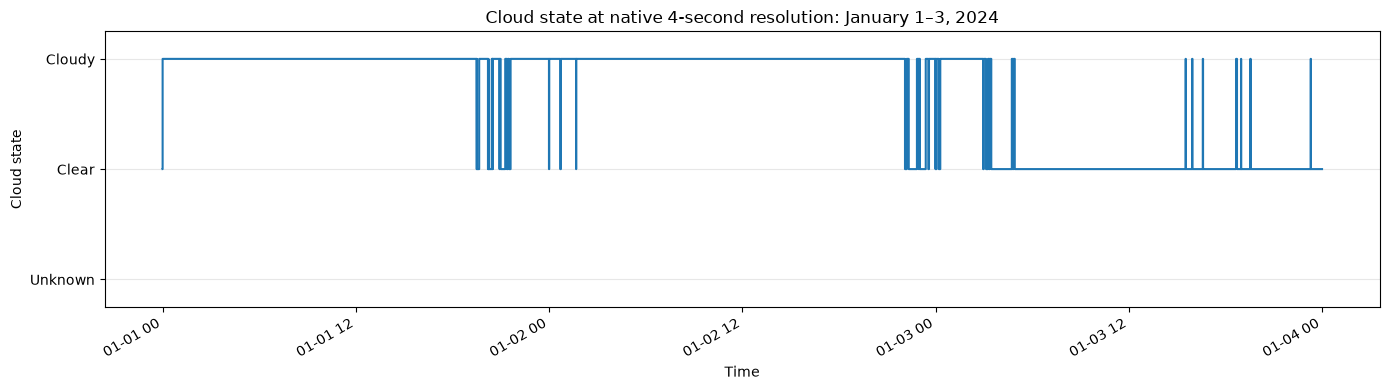

In [8]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.step(
    cloud_state_df.index,
    cloud_state_df["cloud_state"],
    where="post",
)
ax.set_yticks([-1, 0, 1], labels=["Unknown", "Clear", "Cloudy"])
ax.set_ylim(-1.25, 1.25)
ax.set_xlabel("Time")
ax.set_ylabel("Cloud state")
ax.set_title("Cloud state at native 4-second resolution: January 1–3, 2024")
ax.grid(True, axis="y", alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

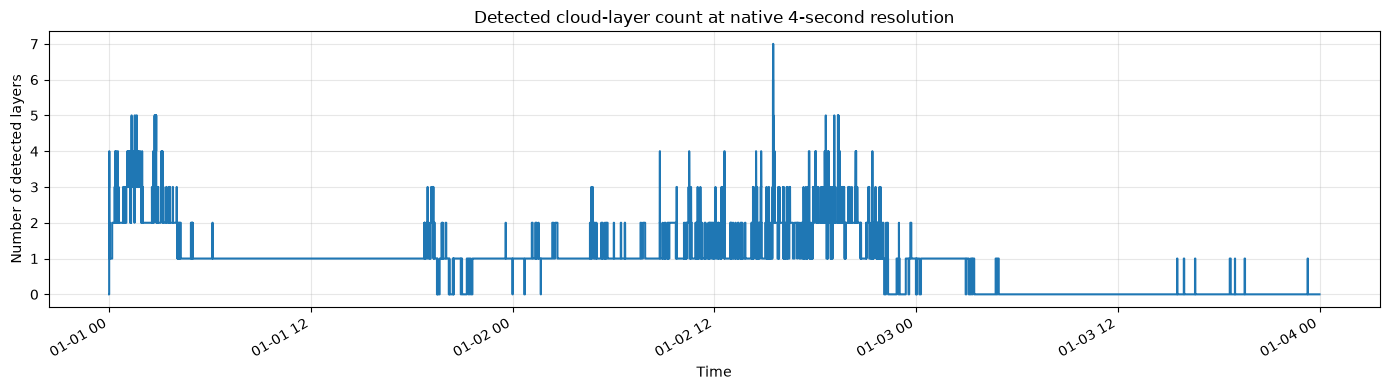

In [9]:
#Inspecting the number of detected layers

fig, ax = plt.subplots(figsize=(14, 4))
ax.step(
    cloud_state_df.index,
    cloud_state_df["n_cloud_layers"],
    where="post",
)
ax.set_xlabel("Time")
ax.set_ylabel("Number of detected layers")
ax.set_title("Detected cloud-layer count at native 4-second resolution")
ax.grid(True, alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


### Interpretation 

Cloudy periods can contain multiple layers. The number of detected layers reaches seven in this sample, while many cloudy observations have only one or two. 

The number of cloud layers is a promising candidate predictor: it describes more than whether a cloud is present; it also summarizes the complexity of the observed vertical structure. 

NOTE: One distinction to preserve is that these are **detected hydrometeor layers from the combined radar and lidar product**, not a direct guarantee that every layer is observed equally well by the radar itself. 

## 8. Identify preliminary clear and cloudy runs

A **run** is a consecutive sequence of observations with the same known state. A change from cloudy to clear starts a new run. 

For this summary, an unknown timestamp breaks a run, and any time interval other than four seconds breaks a run. We will use the number of timestamps multiplied by four seconds as an approximate sampled duration. 

In [10]:
runs = cloud_state_df[["cloud_state"]].copy()
runs["time"] = runs.index

time_step_seconds = runs.index.to_series().diff().dt.total_seconds()
previous_state = runs["cloud_state"].shift()

new_run = ( #Define a new run
    runs["cloud_state"].ne(previous_state)
    | time_step_seconds.ne(4)
    | runs["cloud_state"].eq(-1)
    | previous_state.eq(-1)
)
runs["run_id"] = new_run.cumsum().to_numpy()

known_runs = runs[runs["cloud_state"].isin([0, 1])]
event_summary = (
    known_runs.groupby("run_id")
    .agg(
        cloud_state=("cloud_state", "first"),
        start_time=("time", "first"),
        end_time=("time", "last"),
        n_timestamps=("cloud_state", "size"),
    )
)

event_summary["state_label"] = event_summary["cloud_state"].map(
    {1: "Cloudy", 0: "Clear"}
)
event_summary["approx_duration_seconds"] = (
    event_summary["n_timestamps"] * 4
)
event_summary["approx_duration_minutes"] = (
    event_summary["approx_duration_seconds"] / 60
)

event_summary.head(10)

,cloud_state,start_time,end_time,n_timestamps,state_label,approx_duration_seconds,approx_duration_minutes
run_id,,,,,,,
1,0,2024-01-01 00:00:00,2024-01-01 00:00:04,2,Clear,8,0.133333
2,1,2024-01-01 00:00:08,2024-01-01 19:30:04,17550,Cloudy,70200,1170.000000
3,0,2024-01-01 19:30:08,2024-01-01 19:31:08,16,Clear,64,1.066667
4,1,2024-01-01 19:31:12,2024-01-01 19:31:32,6,Cloudy,24,0.400000
5,0,2024-01-01 19:31:36,2024-01-01 19:39:32,120,Clear,480,8.000000
6,1,2024-01-01 19:39:36,2024-01-01 20:12:16,491,Cloudy,1964,32.733333
7,0,2024-01-01 20:12:20,2024-01-01 20:14:16,30,Clear,120,2.000000
8,1,2024-01-01 20:14:20,2024-01-01 20:14:36,5,Cloudy,20,0.333333
9,0,2024-01-01 20:14:40,2024-01-01 20:26:24,177,Clear,708,11.800000


In [11]:
#We can then summarize run durations by state
run_duration_summary = (
    event_summary.groupby("state_label")["approx_duration_minutes"]
    .agg(
        n_runs="count",
        mean_minutes="mean",
        median_minutes="median",
        minimum_minutes="min",
        maximum_minutes="max",
    )
)

display(run_duration_summary)

print("Number of known cloudy/clear runs:", len(event_summary))
print("Number of unknown timestamps:", int((cloud_state_df["cloud_state"] == -1).sum()))


,n_runs,mean_minutes,median_minutes,minimum_minutes,maximum_minutes
state_label,,,,,
Clear,35,38.683810,5.466667,0.133333,636.533333
Cloudy,34,87.237255,4.433333,0.333333,1225.000000


Number of known cloudy/clear runs: 69
Number of unknown timestamps: 0


### Interpretation

There is a lot to interpret here. The average cloudy run is approximately 87 minutes, but the median is only about 4.4 minutes. 

Similarly, the mean clear-run duration is nearly 39 minutes, while the median is about 5.5 minutes.

This tells us that the duration distributions are **strongly right-skewed**: many relatively short runs coexist with a small number of very long runs. 

Therefore, we should not use the mean run duration alone to choose a prediction horizon. The median gives a better sense of the middle of the observed run-duration distribution, but even that is only a preliminary indicator based on three days. 

Also note, very short runs could represent genuine transitions, brief changes in detection, or sensitivity in the cloud-layer classification. We should investigate these before assuming that every four-second state change represents a meaningful atmospheric event. 

## 9. Check for immediate cloudy/clear transitions

Here, we should investigate what prediction horizon is actually scientifically useful. We can measure the changes between adjacent four-second observations. 

In [12]:
# Count only adjacent pairs that are both known and exactly four seconds apart.
previous = cloud_state_df["cloud_state"].shift()
continuous_step = time_step_seconds.eq(4)
known_pair = ( #Define a known pair 
    cloud_state_df["cloud_state"].isin([0, 1])
    & previous.isin([0, 1])
    & continuous_step
)

# Count the number of transitions between known states
transition_counts = pd.crosstab(
    previous[known_pair].map({0: "Clear", 1: "Cloudy"}),
    cloud_state_df.loc[known_pair, "cloud_state"].map({0: "Clear", 1: "Cloudy"}),
).reindex(index=["Clear", "Cloudy"], columns=["Clear", "Cloudy"], fill_value=0)

transition_counts.index.name = "State at previous timestamp"
transition_counts.columns.name = "State at current timestamp"
display(transition_counts)

# Count the number of comparable pairs and the number of state changes among them
n_comparable_pairs = int(known_pair.sum())
n_state_changes = int(
    (cloud_state_df.loc[known_pair, "cloud_state"].to_numpy()
     != previous[known_pair].to_numpy()).sum()
)
print("Adjacent known 4-second pairs:", n_comparable_pairs)
print("State changes among those pairs:", n_state_changes)
print(
    "Transition rate among adjacent known pairs:",
    n_state_changes / n_comparable_pairs if n_comparable_pairs else np.nan,
)


State at current timestamp,Clear,Cloudy
State at previous timestamp,,
Clear,20274,34
Cloudy,34,44457


Adjacent known 4-second pairs: 64799
State changes among those pairs: 68
Transition rate among adjacent known pairs: 0.0010493989104770134


### Interpretation

There were 64,799 adjacent pairs of observations, of which 68 changed state. That gives a four-second transition rate of approximately 0.105%. 

In other words, the state remains unchanged across approximately 99.895% of adjacent four-second pairs in this sample. Thats not really surprising, but reveals a modeling issue: 

**Predicting cloud state just four seconds into the future would be very easy to do by predicting that the current state remains unchanged**. We need to avoid this, such a model could appear highly accurate without having any substance. 

Therefore, we need to determine how much information the recent cloud state and structure provide about the state in a meaningful future interval. 

## 10. Conclusions

The cloud-state construction sucessfully converts the QC-processed KAZR files into a continuous timestamp-level time series. Across the three test days, all 64,800 expected timestamps are present, the sampling interval remains consistently four seconds, and no unkown cloud states or temporal gaps are observed.

The results reveal substantial variability in cloud conditions. January 1 and January 2 were predominantly cloudy, whereas January 3 was clear. The number of detected hydrometeor layers varies over time, suggesting that cloud structure may provide useful information beyond a binary cloud-state indicator. 

Cloud-state runs have strongly right-skewed distributions. Although median clear and cloudy runs last approximately five and four minutes, respectively, some runs persist for many hours. Likewise, only 68 of 64,799 adjacent four-second observation pairs change state. These results indicate that the native sampling frequency is much faster than most observed state transitions and that a prediction based on the immediately following observation is insufficient. 

These findings support using cloud state as the foundation of the persistence analysis, but the three day sample is too limited to establish representative event-duration distributions or select a final prediction horizon. The aggregation interval and target definition should be investigated using additional observations. 

## 11. Next steps

The next steps will examine cloud-event durations and state transitions in greater detail, including the distribution of short-lived events and the influence of exceptionally long cloudy and clear periods. The analysis will then compare candidate temporal aggregation intervals and determine how persistence or dissipation should be defined. 

Once these decisions are supported by data, the feature-engineering and target-construction stages can be implemented. The eventual pipeline should apply QC in memory, construct cloud state and predictors, create the future outcome, and save the final modeling dataset. 